# Implementing Memory Aware Agents · Memorizz edition
## Build a personal travel assistant with Oracle AI Database

**Maven · Agent Memory · Cohort 2**

The same travel assistant as the from-scratch notebook, built with the
published **Memorizz** package. Memorizz supplies the agent loop (**MemAgent**)
and every memory type, and stores each one in its own Oracle table:
knowledge, conversation, entities, workflows, summaries, tools, tool results
and the semantic cache. Claude runs through Memorizz's **Anthropic** provider
and Tavily through its **TavilyProvider**.

The from-scratch notebook shows how each memory works by writing it by hand.
This notebook shows how to get the same behaviour from a framework, and where
the application still has to write code itself.

Search results are evidence with a source URL, not confirmed fares or
reservations. This lesson ends with a grounded shortlist and supplier links.

### Install the notebook packages

Use a **Python 3.11 or 3.12** kernel. Open this notebook from the `cohort_2` folder so the companion requirements files are available. Run the next cell before the lesson imports: **%pip** installs into the Python environment used by this notebook's active kernel.

`requirements-memorizz.txt` installs the tested lesson dependencies, including **sentence-transformers** for local embeddings, **oracledb** and **langchain-oracledb** for Oracle memory, **anthropic** for generation, and **tavily-python** for live search. It also installs the published **Memorizz** package. 

After the first installation finishes, **restart the kernel**, then run the lesson cells in order. Package installation needs internet access; it does not need your provider API keys.

In [1]:
# Install packages into this notebook's active Python kernel.
%pip install -r requirements-memorizz.txt

### The Parts we will assemble

| Part | Component | Memorizz piece |
|---|---|---|
| 0 | Setup | OracleProvider, Anthropic provider, TavilyProvider |
| 1 | Embedding model | A local encoder behind Memorizz's embedding interface |
| 2 | Retrieval pipeline | KnowledgeBase ingestion and HNSW search in Oracle |
| 3 | Reranker | A hosted Hugging Face cross-encoder over KnowledgeBase candidates |
| 4 | RAG | KnowledgeBase passages answered by the Anthropic provider |
| 5 | Agentic RAG | MemAgent choosing between web search and the knowledge base |
| 6 | Session memory | The current trip kept in EntityMemory |
| 7 | Semantic cache | SemanticCache |
| 8 | Conversational memory | MemAgent conversation history and entity fact capture |
| 9 | Toolbox memory | Toolbox plus MemAgent's semantic tool routing |
| 10 | Workflow memory | Workflow records written by MemAgent |
| 11 | Compaction & compression | Tool-result offloading, tool logs and summaries |
| 12 | Integrated assistant | One MemAgent with every memory type |

### Reference architecture

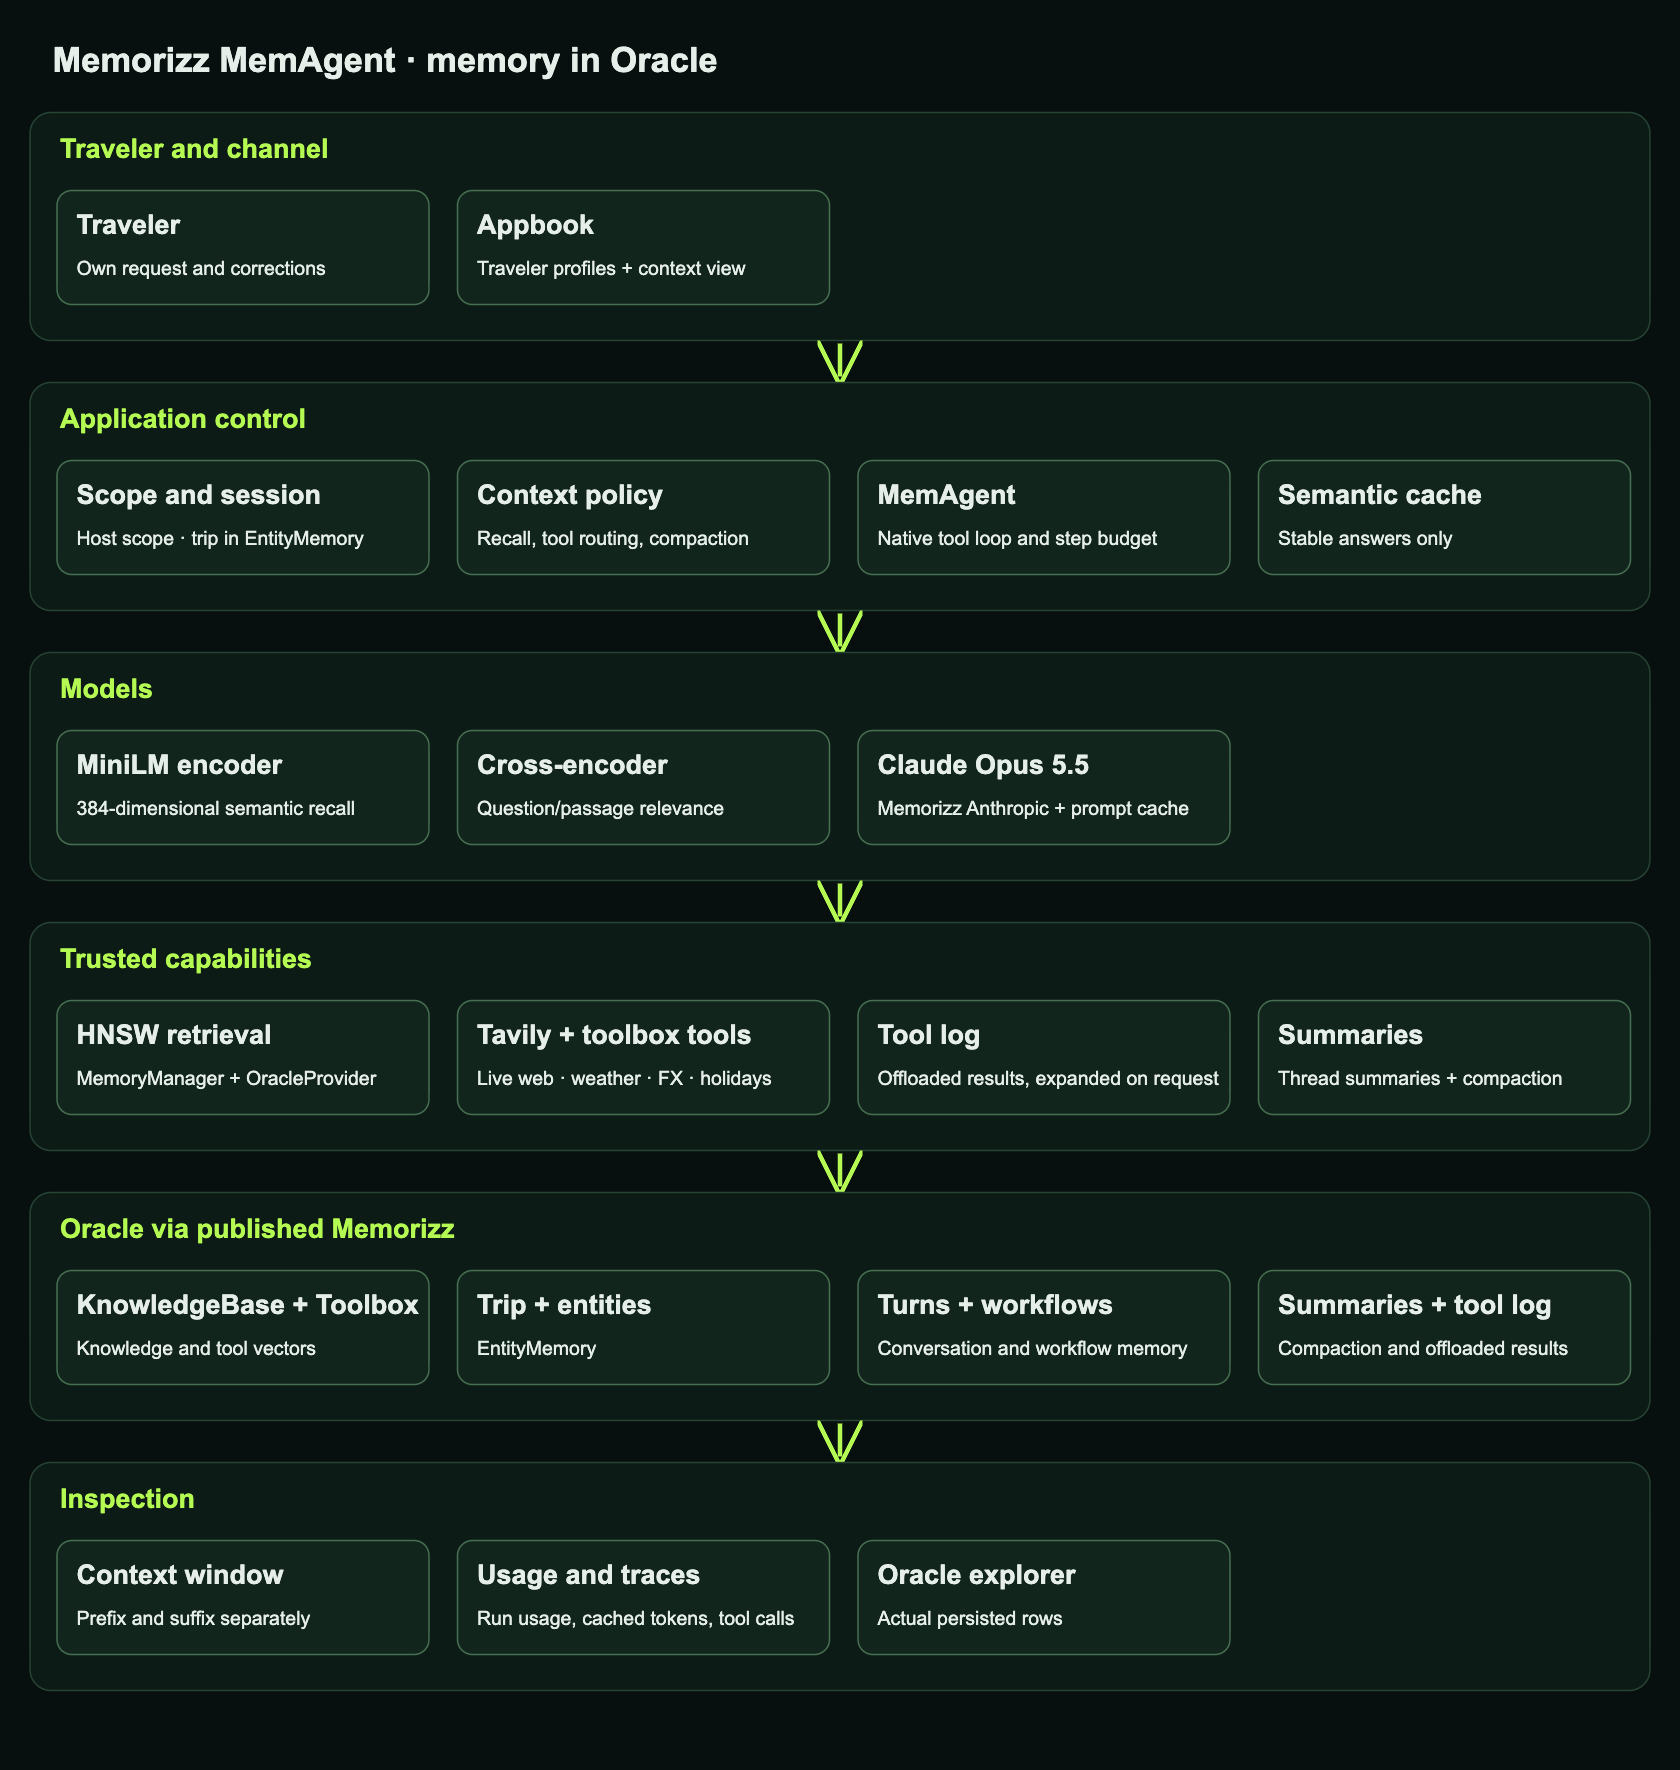

The appbook's [interactive architecture](http://localhost:8031/#architecture)
includes a native **MemAgent** lane and compares it with the custom loop and an
append-only agent.

**Memory** is information retained for future selection. **Context** is the
information chosen for one call. MemAgent selects context from memory on every
turn; this notebook makes those selections visible.

# Part 0 · Set up the classroom environment

Run the install cell above once, restart the kernel, then run these cells in
order. You need an Oracle AI Database schema with vector support, an Anthropic key,
a Tavily key and a Hugging Face access token.

In [2]:
import json
import os
import time
import hashlib

from dataclasses import dataclass
from datetime import datetime, timezone
from getpass import getpass
from importlib.metadata import version

import numpy as np
import oracledb
import pandas as pd

from IPython.display import display

import memorizz
from memorizz import MemAgent
from memorizz.embeddings import BaseEmbeddingProvider
from memorizz.enums.memory_type import MemoryType
from memorizz.internet_access.providers.tavily import TavilyProvider
from memorizz.llms.anthropic import Anthropic
from memorizz.long_term.procedural.toolbox import Toolbox
from memorizz.long_term.semantic.entity_memory import EntityMemory
from memorizz.long_term.semantic.knowledge_base import KnowledgeBase
from memorizz.memory_provider.oracle import OracleConfig, OracleProvider
from memorizz.short_term_memory.semantic_cache import SemanticCache, SemanticCacheConfig
from memorizz.tooling import ContextPolicy, ToolResultPolicy

MEMORIZZ_VERSION = version("memorizz")
print("Memorizz", MEMORIZZ_VERSION)

Memorizz 0.17.23


### Part 0.1 · Private keys and readable records

**request_secret(name)** asks for a hidden value with getpass. The validation
runner sets NOTEBOOK_USE_ENV_KEYS=1 to read keys from its environment instead.
**pretty(value)** prints readable JSON. **digest(value)** turns a value into a
stable ID; it is not encryption.

In [3]:
def request_secret(name):
    if os.getenv("NOTEBOOK_USE_ENV_KEYS") == "1":
        value = os.environ.get(name, "").strip()
    else:
        value = getpass(f"Enter {name}: ").strip()

    if not value:
        raise ValueError(f"{name} is required.")

    return value


def pretty(value):
    return json.dumps(value, indent=2, ensure_ascii=False, default=str)


def digest(value):
    encoded = json.dumps(value, sort_keys=True, default=str).encode()
    return hashlib.sha256(encoded).hexdigest()

### Part 0.2 · Trusted traveler scope

**Scope** carries application-owned tenant, user and thread identifiers.
Memorizz calls the traveler's memory bucket **memory_id**, the person
**user_id** and the conversation **thread_id**. The host sets them on every
call; the model never chooses them.

In [4]:
@dataclass(frozen=True)
class Scope:
    tenant_id: str
    user_id: str
    thread_id: str

    @property
    def owner(self):
        return digest([self.tenant_id, self.user_id])


SCOPE = Scope(
    tenant_id=os.getenv("TRAVEL_TENANT", "cohort-2"),
    user_id=os.getenv("TRAVEL_USER", "local-traveler"),
    thread_id=os.getenv("TRAVEL_THREAD", "travel-planning"),
)

### Part 0.3 · Oracle credentials

Use a dedicated learner schema, never SYS or SYSTEM. Memorizz opens its own
connection pool in Part 1. The plain connection below is only for looking at
the tables Memorizz creates.

In [5]:
DB_USER = os.getenv("ORACLE_USER") or input("Oracle schema user: ").strip()
DB_DSN = os.getenv("ORACLE_DSN") or input("Oracle DSN: ").strip()
DB_PASSWORD = os.getenv("ORACLE_PASSWORD") or getpass("Oracle password: ")

if DB_USER.lower() in {"sys", "system"}:
    raise ValueError("Use a dedicated learner schema.")

conn = oracledb.connect(user=DB_USER, password=DB_PASSWORD, dsn=DB_DSN)


def rows(sql, binds=None):
    with conn.cursor() as cursor:
        cursor.execute(sql, binds or {})
        names = [column[0].lower() for column in cursor.description]
        return [dict(zip(names, record)) for record in cursor.fetchall()]

### Part 0.4 · Claude and Tavily through Memorizz

**Anthropic** is Memorizz's Claude provider. Prompt caching is on by default.
MemAgent uses it for every decision, and **generate_text(prompt, instructions)**
handles the few direct calls in this notebook. **TavilyProvider** is
Memorizz's web-search provider.

**generate(prompt, instructions, purpose)** wraps generate_text and records
each call's time and token usage in **CALLS**, so later Parts can count model
calls.

In [6]:
LLM_MODEL_ID = os.getenv("ANTHROPIC_MODEL", "claude-opus-5-5")

llm = Anthropic(
    api_key=request_secret("ANTHROPIC_API_KEY"),
    model=LLM_MODEL_ID,
    effort="low",
    max_tokens=4096,
)
search = TavilyProvider(api_key=request_secret("TAVILY_API_KEY"))
CALLS = []


def generate(prompt, instructions="Answer the request accurately.", purpose="generation"):
    started = time.perf_counter()
    text = llm.generate_text(prompt, instructions=instructions)
    CALLS.append({"purpose": purpose, "seconds": time.perf_counter() - started, **(llm.get_last_usage() or {})})
    return text

**generate_json(prompt, instructions, purpose)** asks for one JSON object and
allows one correction when the reply is not valid JSON.

In [7]:
def generate_json(prompt, instructions="Return one JSON object.", purpose="structured generation"):
    for attempt in range(2):
        text = generate(prompt, instructions, purpose).strip()

        if text.startswith("```"):
            text = "\n".join(text.splitlines()[1:-1])

        try:
            value = json.loads(text)
            if isinstance(value, dict):
                return value
            raise ValueError("Expected a JSON object.")
        except ValueError:
            if attempt == 1:
                raise
            prompt += "\nReturn only a valid JSON object, without commentary."

### Experiment · a model call does not remember the previous call

Each call sends only its own prompt. The second call below cannot see the
first one. Memory is what the application stores and sends back.

In [8]:
generate("My favourite seat is the aisle. Reply with OK.", purpose="stateless demo")
print(generate("Which seat do I prefer? If you cannot know, say so.", purpose="stateless demo"))

I can't know that. I don't have any information about your seating preferences, and I don't have memory of past conversations unless they're shared with me here.

If you tell me the context, like a flight, train, theater, or car, I can help you think through the options. For example, on a plane people often choose based on:
- **Window:** a view, a wall to lean on, and no one climbing over you
- **Aisle:** easy access to the restroom and overhead bin, plus a quicker exit
- **Middle:** usually only chosen to sit next to a travel companion

Which kind of seat are you trying to decide on?


### Collect the real trip

**parse_trip(request)** extracts the trip you describe into a record:
origin, destination, dates, budget, currency and constraints. Missing details
stay empty; nothing is invented.

In [9]:
def parse_trip(request):
    return generate_json(
        pretty({"traveler_request": request}),
        instructions=(
            "Extract a travel record from traveler_request. Return one JSON object with keys "
            "origin, destination, departure_date, return_date, budget, currency and constraints. "
            "Dates are ISO dates if fully specified, otherwise null. Constraints is a list. "
            "Unknown values are null. Do not answer the request or invent preferences."
        ),
        purpose="trip extraction",
    )

Describe your own trip when the cell asks. An unattended run reads it from the
**TRAVEL_REQUEST** environment variable instead.

In [10]:
TRAVEL_REQUEST = os.getenv("TRAVEL_REQUEST") or input("Describe the trip you want to research: ").strip()
TRIP = parse_trip(TRAVEL_REQUEST)
print(pretty(TRIP))

{
  "origin": "London",
  "destination": "Lisbon",
  "departure_date": "2026-12-10",
  "return_date": "2026-12-14",
  "budget": 900,
  "currency": "GBP",
  "constraints": [
    "flight options",
    "quiet hotel near the centre",
    "transport from the airport to the city"
  ]
}


# Part 1 · Embedding Model: make meaning searchable

An embedding turns text into a vector, so a question can find a stored passage
even when the wording differs. This notebook uses the same local MiniLM encoder
as the from-scratch edition.

Memorizz accepts any encoder that implements its **BaseEmbeddingProvider**
interface: the vector for a text, its size, the model name and a short
description. Oracle stores the vectors; no embedding service is needed.

In [11]:
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMBEDDING_MODEL_ID)
DIMENSIONS = encoder.get_sentence_embedding_dimension()


class LocalEmbeddings(BaseEmbeddingProvider):
    def get_embedding(self, text, **kwargs):
        return encoder.encode([text], normalize_embeddings=True)[0].tolist()

    def get_dimensions(self):
        return DIMENSIONS

    def get_default_model(self):
        return EMBEDDING_MODEL_ID

    def get_provider_info(self):
        return {"provider": "local", "model": EMBEDDING_MODEL_ID, "dimensions": DIMENSIONS}


embeddings = LocalEmbeddings()

### Experiment · compare meanings

Because the vectors have unit length, their dot product is the cosine
similarity: higher means closer in meaning. The two flight sentences should
score higher with each other than with the hotel sentence.

In [12]:
examples = [
    "I want a nonstop flight.",
    "I prefer a direct flight.",
    "The hotel has a quiet refundable room.",
]
vectors = np.array([embeddings.get_embedding(text) for text in examples])

display(pd.DataFrame([
    {"first": examples[i], "second": examples[j], "cosine similarity": round(float(vectors[i] @ vectors[j]), 3)}
    for i, j in [(0, 1), (0, 2), (1, 2)]
]))

,first,second,cosine similarity
0,I want a nonstop flight.,I prefer a direct flight.,0.690
1,I want a nonstop flight.,The hotel has a quiet refundable room.,0.157
2,I prefer a direct flight.,The hotel has a quiet refundable room.,0.134


### Part 1.1 · Create the Oracle provider

**OracleProvider** is Memorizz's Oracle store. It creates one table per memory
type and an HNSW vector index on each, the first time that memory is searched.
**in_database_embedding=False** uses the local encoder above, and
**vector_search_mode="approximate"** makes searches use the HNSW indexes.

In [13]:
provider = OracleProvider(OracleConfig(
    user=DB_USER,
    password=DB_PASSWORD,
    dsn=DB_DSN,
    in_database_embedding=False,
    embedding_provider=embeddings,
    index_policy="lazy",
    vector_search_mode="approximate",
    pool_min=1,
    pool_max=3,
))

assert provider.preflight()["ok"], "Check the schema's privileges and vector memory."
print("Connected to Oracle as", DB_USER)

Connected to Oracle as AMR_D10F1C880B


# Part 2 · Retrieval Pipeline: turn live sources into durable evidence

The write path searches the web, stores each result as knowledge with its URL,
and embeds it. The read path finds the passages closest to a question.

**KnowledgeBase** is Memorizz's knowledge store. **ingest_knowledge** chunks a
text, embeds each chunk and stores it under a **namespace**, here *policy*.
**ingest_results(results, namespace, scope)** stores each Tavily result with its
title, URL and retrieval time.

In [14]:
knowledge = KnowledgeBase(provider)


def ingest_results(results, namespace="policy", scope=SCOPE):
    retrieved_at = datetime.now(timezone.utc).isoformat()
    ids = []

    for result in results:
        if not result.snippet.strip():
            continue

        ids.append(knowledge.ingest_knowledge(
            result.snippet,
            namespace=namespace,
            chunk_size=800,
            chunk_overlap=80,
            user_id=scope.owner,
            metadata={"url": result.url, "title": result.title, "retrieved_at": retrieved_at},
        ))

    return ids

**POLICY_QUERY** is a question about a travel rule that affects your trip, such as
an airline's checked-baggage allowance or a hotel's cancellation policy, for
example *TAP Air Portugal economy checked baggage allowance*. You type it when the
cell asks; an unattended run reads it from the **TRAVEL_POLICY_QUERY** environment
variable instead. The cell searches the live web and stores the results as
**policy** knowledge. Parts 2, 3 and 4 reuse the same question.

In [15]:
POLICY_QUERY = os.getenv("TRAVEL_POLICY_QUERY") or input("Policy query for your trip: ").strip()
policy_results = search.search(POLICY_QUERY, max_results=5)
knowledge_ids = ingest_results(policy_results)

display(pd.DataFrame([{"title": r.title, "url": r.url, "score": r.score} for r in policy_results]))
print("Stored", len(knowledge_ids), "results as policy knowledge")

Stored 5 results as policy knowledge


,title,url,score
0,Find Cheap Flights and Deals: Compare & Book |...,https://www.flytap.com/en_us,0.546957
1,TAP Air Portugal,https://www.mapquest.com/us/florida/tap-air-po...,0.366364
2,TAP Air Portugal - Wikipedia,https://en.wikipedia.org/wiki/TAP_Air_Portugal,0.325500
3,TAP Air Portugal | flyTAP Official Website,https://www.flytap.com,0.234486
4,TAP Air Portugal,https://tavily.com/knowledge/company/uQfwJ0hAgAQz,0.181728


### Part 2.1 · Search the knowledge base

**retrieve(question, namespace, k, scope)** calls
**retrieve_knowledge_by_query**. Memorizz embeds the question and runs an
approximate HNSW search in Oracle, limited to this traveler's knowledge.
Each result keeps its text, URL and similarity score.

In [16]:
def retrieve(question, namespace="policy", k=6, scope=SCOPE):
    return knowledge.retrieve_knowledge_by_query(question, namespace=namespace, limit=k, user_id=scope.owner)

The table shows the closest passages, and the second query lists the vector
indexes Memorizz created in your schema.

In [17]:
candidates = retrieve(POLICY_QUERY)

display(pd.DataFrame([
    {"rank": rank, "title": (item.get("title") or "")[:50], "score": round(float(item["score"]), 3), "url": item.get("url")}
    for rank, item in enumerate(candidates, start=1)
]).set_index("rank"))

display(pd.DataFrame(rows("""
    SELECT table_name, index_name, status
    FROM user_indexes
    WHERE index_type = 'VECTOR'
    ORDER BY table_name
""")))

,title,score,url
rank,,,
1,TAP Air Portugal - Wikipedia,0.621,https://en.wikipedia.org/wiki/TAP_Air_Portugal
2,TAP Air Portugal,0.593,https://www.mapquest.com/us/florida/tap-air-po...
3,TAP Air Portugal,0.494,https://tavily.com/knowledge/company/uQfwJ0hAgAQz
4,TAP Air Portugal | flyTAP Official Website,0.483,https://www.flytap.com
5,TAP Air Portugal,0.472,https://www.mapquest.com/us/florida/tap-air-po...
6,TAP Air Portugal - Wikipedia,0.442,https://en.wikipedia.org/wiki/TAP_Air_Portugal


,table_name,index_name,status
0,KNOWLEDGE_BASE,IDX_KB_VEC,VALID


# Part 3 · Reranker: reorder retrieved passages by relevance

The embedding model scores the question and each passage separately. A
cross-encoder reads them together and estimates how relevant the passage is,
then reorders the candidates so the most relevant come first.

This edition uses a **hosted** reranker: the same cross-encoder,
[cross-encoder/ms-marco-MiniLM-L6-v2](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2),
that the from-scratch notebook runs locally and that Oracle can load as an
in-database ONNX model, served by Hugging Face Inference Providers. It needs a
free Hugging Face access token, **HF_TOKEN**.

Memorizz can attach a hosted reranker to MemAgent, but its built-in options are
Voyage, Cohere and OpenAI, not Hugging Face. So **rerank(question, candidates,
keep)** calls the endpoint directly: it sends the question and the candidate
texts, and receives a relevance score for each.

In [18]:
import requests

RERANKER_MODEL_ID = "cross-encoder/ms-marco-MiniLM-L6-v2"
RERANK_URL = f"https://router.huggingface.co/hf-inference/models/{RERANKER_MODEL_ID}"
HF_TOKEN = request_secret("HF_TOKEN")


def rerank(question, candidates, keep=3):
    response = requests.post(
        RERANK_URL,
        headers={"Authorization": f"Bearer {HF_TOKEN}"},
        json={"inputs": {"query": question, "texts": [item["content"] for item in candidates]}},
        timeout=60,
    )
    response.raise_for_status()

    scores = {row["index"]: float(row["score"]) for row in response.json()}
    order = sorted(scores, key=scores.get, reverse=True)
    return [{**candidates[index], "rerank_score": scores[index]} for index in order[:keep]]

Compare the vector order with the reranked order for the same candidates.

In [19]:
reranked = rerank(POLICY_QUERY, candidates, keep=len(candidates))

display(pd.DataFrame([
    {"reranked position": position, "title": (item.get("title") or "")[:50],
     "vector rank": next(i for i, c in enumerate(candidates, start=1) if c is item or c["_id"] == item["_id"]),
     "rerank score": round(item["rerank_score"], 2)}
    for position, item in enumerate(reranked, start=1)
]).set_index("reranked position"))

,title,vector rank,rerank score
reranked position,,,
1,TAP Air Portugal - Wikipedia,1,3.21
2,TAP Air Portugal,2,2.34
3,TAP Air Portugal | flyTAP Official Website,4,-0.69
4,TAP Air Portugal,3,-1.08
5,TAP Air Portugal - Wikipedia,6,-1.91
6,TAP Air Portugal,5,-7.69


# Part 4 · RAG: answer from selected evidence

**rag_answer(question, trip)** retrieves knowledge, keeps the three best
passages after reranking and asks Claude to answer from them with the trip
stated explicitly. The model sees only these passages and the trip, so every
claim can be traced to a URL.

In [20]:
def rag_answer(question, trip, scope=SCOPE):
    passages = rerank(question, retrieve(question, scope=scope), keep=3)
    evidence = [{"url": item.get("url"), "title": item.get("title"), "text": item["content"]} for item in passages]

    answer = generate(
        pretty({"question": question, "trip": trip, "evidence": evidence}),
        instructions=(
            "Answer the question using only the evidence. Cite the URL for each claim. "
            "Say what the evidence does not cover. Do not claim to book anything."
        ),
        purpose="RAG answer",
    )
    return {"answer": answer, "sources": [item["url"] for item in evidence]}

Ask your policy question with your trip as explicit context.

In [21]:
rag_result = rag_answer(POLICY_QUERY, TRIP)
print(rag_result["answer"])
print(pretty(rag_result["sources"]))

**Short answer:** The evidence doesn't state TAP Air Portugal's economy checked baggage allowance. None of the three sources gives a number of bags, a weight limit or a fee.

**What the evidence does say**

- **Economy fare names:** TAP's economy fares are tap|plus, tap|classic, tap|basic and tap|discount. This suggests the baggage allowance probably differs by fare, but the source doesn't say how. (https://en.wikipedia.org/wiki/TAP_Air_Portugal)
- **Aircraft on your route:** Medium-haul flights such as London–Lisbon use Airbus A319, A320 and A321 aircraft with two cabins, economy and executive. TAP has no first class. (https://en.wikipedia.org/wiki/TAP_Air_Portugal)
- **Airline basics:** TAP is Portugal's flag carrier, based at Lisbon Airport, and a Star Alliance member since 2005. (https://en.wikipedia.org/wiki/TAP_Air_Portugal)
- **Official website:** The excerpt from flytap.com only covers TAP Miles&Go and hotel discounts. It has no baggage details. (https://www.flytap.com)
- **Map

# Part 5 · Agentic RAG: choose which evidence to fetch

In RAG the application decides what to retrieve. In **agentic RAG** the model
decides: search the live web, look up stored knowledge, or answer.

**MemAgent** is Memorizz's agent loop. Given an **internet_access_provider**, it
offers Claude an **internet_search** tool; with **KNOWLEDGE_BASE** memory it
also offers **knowledge_base_lookup**. MemAgent validates each tool call, runs
it, stores the outcome and repeats until Claude answers or **max_steps** is
reached. The from-scratch notebook writes this loop and its action protocol by
hand.

**make_agent(name, memory_types, instruction, ...)** builds each MemAgent in this
notebook with the same Claude provider, Oracle store and step budget.
**automations_enabled=False** leaves out Memorizz's timer and scheduling tools,
which a travel assistant does not need. **ToolResultPolicy(offload_above_chars=2000)**
keeps large search results out of the prompt; Part 11 looks at what it stores.

In [22]:
TRAVEL_INSTRUCTION = (
    "You are a travel research assistant. Research flights, hotels, transport and travel rules "
    "with the available tools, and cite the URL of every source you use. Treat search results as "
    "evidence that can change, not confirmed prices or availability. Never claim to book anything. "
    "Use the current trip and remembered preferences. If something is unknown, say so."
)


def make_agent(name, memory_types, instruction=TRAVEL_INSTRUCTION, **options):
    return MemAgent(
        name=name,
        model=llm,
        memory_provider=provider,
        memory_types=memory_types,
        instruction=instruction,
        max_steps=8,
        automations_enabled=False,
        **options,
    )


research_agent = make_agent(
    "travel-research",
    [MemoryType.CONVERSATION_MEMORY, MemoryType.KNOWLEDGE_BASE, MemoryType.WORKFLOW_MEMORY],
    internet_access_provider=search,
    tool_result_policy=ToolResultPolicy(offload_above_chars=2000),
)

**run_agent(agent, request, context, scope)** runs one turn for this traveler
and thread. It records MemAgent's trace events, so the result lists every tool
call with its arguments, alongside Memorizz's usage and context-window counts.
MemAgent reports an internal error as text; run_agent raises it instead.

In [23]:
def run_agent(agent, request, context=None, scope=SCOPE):
    events = []
    agent.set_stream_event_callback(events.append)
    started = time.perf_counter()

    try:
        answer = agent.run(
            request,
            memory_id=scope.owner,
            thread_id=scope.thread_id,
            user_id=scope.owner,
            context=context,
        )
    finally:
        agent.set_stream_event_callback(None)

    if answer.startswith("I apologize, but I encountered an error"):
        raise RuntimeError(answer)

    return {
        "answer": answer,
        "seconds": time.perf_counter() - started,
        "tool_calls": [
            {"tool": event["tool_name"], "arguments": event.get("content")}
            for event in events if event.get("trace_kind") == "tool_call"
        ],
        "usage": agent.get_last_run_usage(),
        "context_window": agent.get_context_window_stats(),
    }

Ask for live travel options. The table shows which tools Claude chose and with
what arguments.

In [24]:
research = run_agent(
    research_agent,
    "Find two flight options and one quiet hotel near the centre for my trip. Keep it brief and cite URLs.",
    context={"trip": TRIP},
)

print(research["answer"])
display(pd.DataFrame(research["tool_calls"]))

Here are two flight options and one central hotel for London → Lisbon, 10–14 Dec 2026. The prices are recent guides from search sites, mostly in US dollars. They aren't live fares for your dates, and I haven't booked anything.

**Flights**
1. **easyJet, direct, Gatwick or Luton → Lisbon:** Google Flights lists returns from about $101, usually $110–320. KAYAK's cheapest recent December example was easyJet from Gatwick. Bags cost extra.
   https://www.google.com/travel/flights/flights-from-london-to-lisbon.html
   https://www.kayak.com/flight-routes/London-LON/Lisbon-Humberto-Delgado-LIS
2. **TAP Air Portugal, direct, Heathrow or Gatwick → Lisbon:** returns from about $176, usually $185–355. It flies around 50 times a week. British Airways from Heathrow is similar, usually $200–480.
   https://www.google.com/travel/flights/flights-from-london-to-lisbon.html
   https://www.momondo.com/flights/london/lisbon

Either option should leave plenty of your £900 budget for the hotel.

**Hotel: Hot

,tool,arguments
0,internet_search,"{""query"": ""London to Lisbon flights December 2..."
1,internet_search,"{""query"": ""quiet boutique hotel central Lisbon..."
2,retrieve_tool_log_entry,"{""tool_log_id"": ""ae3d2cf2-3e46-4ad2-a7ba-d801f..."
3,retrieve_tool_log_entry,"{""tool_log_id"": ""e00d3989-2d5d-4a6b-9ea3-8f549..."


# Part 6 · Session Memory: resume the active trip

Session memory is the current working state: the trip being planned now.
Memorizz has no separate session store, so the trip is kept as an entity in
**EntityMemory**, one record named *current trip* with one attribute per field.
Upserting the same name updates that record in place, so a later conversation,
or a restarted notebook, can resume it.

**save_trip** and **load_trip** are the application's session layer. The trip
reaches the agent through **run(context=...)** on every turn.

In [25]:
entity_memory = EntityMemory(provider)


def save_trip(trip, scope=SCOPE):
    attributes = [
        {"name": key, "value": value if isinstance(value, str) else json.dumps(value)}
        for key, value in trip.items() if value not in (None, "", [])
    ]
    return entity_memory.upsert_entity(
        name="current trip", entity_type="trip", attributes=attributes,
        memory_id=scope.owner, user_id=scope.owner,
    )


def load_trip(scope=SCOPE):
    entity = entity_memory.get_entity_by_name("current trip", memory_id=scope.owner, user_id=scope.owner)
    return {attribute["name"]: attribute["value"] for attribute in entity["attributes"]} if entity else {}

Save the trip from Part 0, then read it back from Oracle.

In [26]:
save_trip(TRIP)
print(pretty(load_trip()))

{
  "origin": "London",
  "destination": "Lisbon",
  "departure_date": "2026-12-10",
  "return_date": "2026-12-14",
  "budget": "900",
  "currency": "GBP",
  "constraints": "[\"flight options\", \"quiet hotel near the centre\", \"transport from the airport to the city\"]"
}


# Part 7 · Semantic Cache: reuse stable answers carefully

A semantic cache returns a stored answer when a new question means the same
as an earlier one, without calling the model. It suits stable explanations,
not live travel prices.

**SemanticCache** is Memorizz's cache, stored in Oracle. It embeds the question
and returns a stored answer when the cosine similarity is at least
**similarity_threshold**. Similarity is 1 minus the cosine distance, so
**similarity_threshold=0.7** accepts any stored question within a distance of 0.3.

**cached_explanation(question, scope)** checks the cache, otherwise asks Claude
and stores the answer.

In [27]:
semantic_cache = SemanticCache(
    SemanticCacheConfig(similarity_threshold=0.7, enable_session_scoping=False, ttl_hours=1),
    memory_provider=provider,
    agent_id="memory-explainer",
    memory_id=SCOPE.owner,
)


def cached_explanation(question, scope=SCOPE):
    cached = semantic_cache.get(question, user_id=scope.owner)
    if cached is not None:
        return {"answer": cached, "cache_hit": True}

    answer = generate(
        question,
        instructions="Explain the agent-memory concept in under 120 words. Do not research travel offers.",
        purpose="semantic cache miss",
    )
    semantic_cache.set(question, answer, user_id=scope.owner)
    return {"answer": answer, "cache_hit": False}

### Experiment · a miss, then a hit for a similar question

The first question produces an actual answer. The second asks the same thing in
different words (*pick* instead of *choose*); it is close enough to return the
stored answer without a model call.

In [28]:
cache_question = "How does retrieval help an agent choose relevant memories?"
similar_question = "How does retrieval help an agent pick relevant memories?"

calls_before = len(CALLS)
started = time.perf_counter()
first = cached_explanation(cache_question)
first_seconds = time.perf_counter() - started

started = time.perf_counter()
second = cached_explanation(similar_question)
second_seconds = time.perf_counter() - started

display(pd.DataFrame([
    {"request": "first", "hit": first["cache_hit"], "seconds": round(first_seconds, 3)},
    {"request": "similar wording", "hit": second["cache_hit"], "seconds": round(second_seconds, 3)},
]))
print("New model calls:", len(CALLS) - calls_before)
assert second["cache_hit"] and first["answer"] == second["answer"]

New model calls: 1


,request,hit,seconds
0,first,False,4.911
1,similar wording,True,0.027


At 0.7 the cache also reuses the answer for a question with the same intent in
very different wording. It does the same for a *different* question about memory.
The next cell asks one of each. With all-MiniLM-L6-v2 both have a similarity of
about 0.75 to the stored question, above the threshold.

In [29]:
checks = {
    "same intent, different wording": "Why retrieve selected memories for an agent's next context?",
    "different question": "How does an agent forget outdated memories?",
}

outcomes = []
for label, question in checks.items():
    reply = cached_explanation(question)
    outcomes.append({
        "question": label,
        "hit": reply["cache_hit"],
        "reused first answer": reply["answer"] == first["answer"],
    })

display(pd.DataFrame(outcomes))
print({key: value for key, value in semantic_cache.statistics().items() if key in ("hits", "misses", "writes", "size")})

{'hits': 3, 'misses': 1, 'writes': 1, 'size': 1}


,question,hit,reused first answer
0,"same intent, different wording",True,True
1,different question,True,True


Wherever **hit** is True, that question received the stored retrieval answer
without a model call. That is correct for the paraphrase. For the question about
forgetting, it is the wrong answer. Similarity alone cannot separate the two,
which is the trade-off: a looser threshold reuses more answers but risks
answering a different question. That is why only stable explanations use this
cache and live travel requests bypass it.

# Part 8 · Conversational Memory: events and current entities

MemAgent stores every user and assistant turn as **conversation memory** and
reloads the recent turns of the thread on the next call.

**Entity memory** keeps durable facts about a person, such as seat or hotel
preferences. **capture_entity_facts(text)** asks Claude to extract the facts
stated in a message and stores them as attributes of the traveler's entity,
each with its source thread. A later correction updates the attribute.

In [30]:
chat_agent = make_agent(
    "travel-chat",
    [MemoryType.CONVERSATION_MEMORY, MemoryType.ENTITY_MEMORY],
    instruction=(
        "You are a travel assistant. Acknowledge the traveler's message in one or two sentences. "
        "Do not call tools: the application saves preferences itself."
    ),
)


def traveler_facts(scope=SCOPE):
    return [
        {"entity": entity["name"], "attribute": attribute["name"], "value": attribute["value"],
         "updated_at": attribute.get("updated_at")}
        for entity in entity_memory.list_entities(memory_id=scope.owner, user_id=scope.owner)
        if entity.get("entity_type") != "trip"
        for attribute in entity.get("attributes", [])
    ]

State a preference in your own words. The turn is stored as conversation, and
its facts are captured as entity attributes. An unattended run reads the text
from **TRAVEL_PREFERENCE_TEXT**.

In [31]:
PREFERENCE_TEXT = os.getenv("TRAVEL_PREFERENCE_TEXT") or input("A travel preference to remember: ").strip()

reply = run_agent(chat_agent, PREFERENCE_TEXT, context={"trip": load_trip()})
chat_agent.capture_entity_facts(PREFERENCE_TEXT, user_id=SCOPE.owner, memory_id=SCOPE.owner, thread_id=SCOPE.thread_id)

print(reply["answer"])
display(pd.DataFrame(traveler_facts()))

Noted: you'd like an aisle seat and a quiet room you can cancel for a refund. When we look at real prices, I'll focus on refundable rates and ask for a quiet room, such as one at the back of Hotel do Chiado. On the flights, I'll favour fares where you can choose your seat, since easyJet charges extra for that.


,entity,attribute,value,updated_at
0,user,seat_preference,aisle seat,2026-11-06T12:15:50.077299+00:00
1,user,hotel_room_preference,"quiet, refundable hotel room",2026-11-06T12:15:50.077299+00:00


Correct a preference. The seat attribute is replaced rather than duplicated, and
the conversation keeps both messages. Entity capture stores lasting facts; a
message such as *for this trip only* may be treated as temporary and not stored.

In [32]:
correction = "Actually, I prefer a window seat, not an aisle seat."
run_agent(chat_agent, correction, context={"trip": load_trip()})
chat_agent.capture_entity_facts(correction, user_id=SCOPE.owner, memory_id=SCOPE.owner, thread_id=SCOPE.thread_id)

display(pd.DataFrame(traveler_facts()))
history = chat_agent.load_conversation_history(memory_id=SCOPE.owner, thread_id=SCOPE.thread_id, user_id=SCOPE.owner)
display(pd.DataFrame([
    {"role": turn["role"], "content": turn["content"][:90]}
    for turn in history if turn["role"] in ("user", "assistant")
]))

,entity,attribute,value,updated_at
0,user,seat_preference,window seat,2026-11-06T12:15:53.653129+00:00
1,user,hotel_room_preference,"quiet, refundable hotel room",2026-11-06T12:15:50.077299+00:00


,role,content
0,user,Find two flight options and one quiet hotel ne...
1,assistant,Here are two flight options and one central ho...
2,user,"I prefer an aisle seat and a quiet, refundable..."
3,assistant,Noted: you'd like an aisle seat and a quiet ro...
4,user,"Actually, I prefer a window seat, not an aisle..."
5,assistant,"Got it, I'll look for a window seat instead of..."


# Part 9 · Toolbox Memory: retrieve the tools a request needs

**Toolbox memory** stores what the agent can do. Each entry is a tool
definition: a name, a description and its parameters, embedded and stored in
Oracle. Instead of placing every tool in every prompt, the agent is offered
only the few that fit the request.

The Python functions stay in the application. A stored definition describes a
tool but cannot add one: only functions registered in this process can run.

The five tools below call real public services that need no API key:
[Open-Meteo](https://open-meteo.com/) for weather and daylight,
[Frankfurter](https://frankfurter.dev/) for European Central Bank exchange
rates and [Nager.Date](https://date.nager.at/) for public holidays.

### Part 9.1 · Five real travel tools

**http_json(url, params)** makes one GET request and returns the JSON body with
the exact URL it called, so a later answer can cite it. **locate(place)**
resolves a place name to coordinates, country code and time zone with the
Open-Meteo geocoder. **trip_window** rejects reversed or overlong date ranges,
and **year_earlier** moves a date back one year.

In [33]:
from datetime import date, timedelta
from zoneinfo import ZoneInfo

import requests


def http_json(url, params):
    response = requests.get(url, params=params, timeout=20)
    response.raise_for_status()
    return response.json(), response.url


def locate(place):
    data, _ = http_json(
        "https://geocoding-api.open-meteo.com/v1/search",
        {"name": place, "count": 1, "language": "en"},
    )
    if not data.get("results"):
        raise ValueError(f"No location found for {place!r}.")

    hit = data["results"][0]
    return {key: hit.get(key) for key in ["name", "country", "country_code", "latitude", "longitude", "timezone"]}


def trip_window(start_date, end_date, longest=31):
    start, end = date.fromisoformat(start_date), date.fromisoformat(end_date)
    if end < start or (end - start).days >= longest:
        raise ValueError(f"Use a date range of 1–{longest} days.")
    return start, end


def year_earlier(day):
    try:
        return day.replace(year=day.year - 1)
    except ValueError:
        # 29 February has no match in the previous year.
        return day.replace(year=day.year - 1, day=28)

**weather_outlook** and **daylight_hours** share one reader, **daily_weather**.
A forecast reaches only about 16 days ahead, so for later dates both tools
return the weather observed on the same dates a year earlier and say so in
**basis**. History is a guide to the season, not a forecast.

In [34]:
def daily_weather(place, start, end, variables):
    where = locate(place)
    today = date.today()

    if today <= start and end <= today + timedelta(days=15):
        endpoint, basis, window = "https://api.open-meteo.com/v1/forecast", "forecast", (start, end)
    else:
        endpoint = "https://archive-api.open-meteo.com/v1/archive"
        basis = "observed on the same dates one year earlier, not a forecast"
        window = (year_earlier(start), year_earlier(end))

    data, url = http_json(endpoint, {
        "latitude": where["latitude"],
        "longitude": where["longitude"],
        "start_date": window[0].isoformat(),
        "end_date": window[1].isoformat(),
        "daily": ",".join(variables),
        "timezone": where["timezone"] or "auto",
    })

    columns = [data["daily"]["time"], *(data["daily"][name] for name in variables)]
    days = [dict(zip(["date", *variables], values)) for values in zip(*columns)]
    return {"location": where, "basis": basis, "units": data["daily_units"], "days": days, "url": url}


def weather_outlook(place: str, start_date: str, end_date: str) -> dict:
    """Daily high and low temperature and rain for a destination and date range.
    Uses the Open-Meteo forecast for dates in the next 16 days; for later dates it
    returns the weather observed on the same dates a year earlier, labelled as history."""
    start, end = trip_window(start_date, end_date)
    today = date.today()
    forecast = today <= start and end <= today + timedelta(days=15)
    rain = "precipitation_probability_max" if forecast else "precipitation_sum"
    return daily_weather(place, start, end, ["temperature_2m_max", "temperature_2m_min", rain])


def daylight_hours(place: str, start_date: str, end_date: str) -> dict:
    """Sunrise, sunset and hours of daylight at a destination for a date range,
    for planning sightseeing, photography or an arrival after dark."""
    start, end = trip_window(start_date, end_date)
    result = daily_weather(place, start, end, ["sunrise", "sunset", "daylight_duration"])

    for day in result["days"]:
        day["daylight_hours"] = round(day.pop("daylight_duration") / 3600, 2)

    return result

**exchange_rate** returns the latest ECB reference rate and its date.
**public_holidays** lists the holidays between two dates. **time_difference**
compares two time zones on a given date, so daylight-saving changes count.
Each docstring is the description that toolbox memory will embed.

In [35]:
def exchange_rate(base: str, quote: str) -> dict:
    """Latest European Central Bank reference exchange rate between two currencies,
    for converting a travel budget. A card or exchange desk charges its own rate."""
    base, quote = base.upper(), quote.upper()
    data, url = http_json("https://api.frankfurter.dev/v1/latest", {"base": base, "symbols": quote})
    return {"base": base, "quote": quote, "rate": data["rates"][quote], "rate_date": data["date"], "url": url}


def public_holidays(country_code: str, start_date: str, end_date: str) -> dict:
    """Public holidays in a country between two dates. Holidays can close shops,
    museums and offices, and make trains, flights and hotels busier."""
    start, end = trip_window(start_date, end_date, longest=366)
    holidays, urls = [], []

    for year in range(start.year, end.year + 1):
        data, url = http_json(f"https://date.nager.at/api/v3/PublicHolidays/{year}/{country_code.upper()}", {})
        urls.append(url)
        holidays += [{
            "date": item["date"],
            "name": item["name"],
            "local_name": item["localName"],
            "nationwide": item["global"],
        } for item in data if start <= date.fromisoformat(item["date"]) <= end]

    return {"country_code": country_code.upper(), "holidays": holidays, "url": urls[0], "urls": urls}


def time_difference(origin: str, destination: str, on_date: str) -> dict:
    """Hours between the origin and destination time zones on a given date,
    for planning around jet lag, arrival times and calls home."""
    places = [locate(origin), locate(destination)]
    day = date.fromisoformat(on_date)
    offsets = [
        datetime(day.year, day.month, day.day, 12, tzinfo=ZoneInfo(place["timezone"])).utcoffset().total_seconds() / 3600
        for place in places
    ]

    return {
        "origin": {"name": places[0]["name"], "timezone": places[0]["timezone"], "utc_offset_hours": offsets[0]},
        "destination": {"name": places[1]["name"], "timezone": places[1]["timezone"], "utc_offset_hours": offsets[1]},
        "destination_minus_origin_hours": offsets[1] - offsets[0],
        "on_date": on_date,
    }


TRAVEL_TOOLS = [weather_outlook, daylight_hours, exchange_rate, public_holidays, time_difference]

Call one tool directly before storing anything. The cell uses the destination
and dates extracted from your own request in Part 0. When your request has no
dates, it says so instead of choosing dates for you.

In [36]:
place = TRIP.get("destination") or "my destination"
dates_known = bool(TRIP.get("departure_date") and TRIP.get("return_date"))

if TRIP.get("destination") and dates_known:
    country = locate(place)["country_code"]
    print(pretty(public_holidays(country, TRIP["departure_date"], TRIP["return_date"])))
else:
    print("Add a destination and travel dates to your request to call a date-based tool.")

{
  "country_code": "PT",
  "holidays": [],
  "url": "https://date.nager.at/api/v3/PublicHolidays/2026/PT",
  "urls": [
    "https://date.nager.at/api/v3/PublicHolidays/2026/PT"
  ]
}


### Part 9.2 · Store the tools and let MemAgent route them

**Toolbox.from_functions** stores each function's name, docstring and
signature in Oracle and embeds them. Passed to MemAgent, the toolbox drives
**semantic tool routing**: on each turn MemAgent offers the tools whose
descriptions best match the request.

**ContextPolicy** controls that routing. **tool_top_k=2** offers at most two
tools. **stable_tool_list_tokens=0** turns off the shortcut that sends every
tool when the whole list is small, so routing is visible even with five tools.

In [37]:
toolbox = Toolbox.from_functions(TRAVEL_TOOLS, memory_provider=provider)
TOOL_POLICY = ContextPolicy(stable_tool_list_tokens=0, tool_top_k=2, sticky_tool_limit=0)

tool_agent = make_agent(
    "travel-tools",
    [MemoryType.CONVERSATION_MEMORY, MemoryType.WORKFLOW_MEMORY],
    toolbox=toolbox,
    context_policy=TOOL_POLICY,
)

**preview(question)** asks MemAgent's router which stored tools it would offer,
without calling Claude. The router has no relevance cut-off: it always offers
the tool_top_k closest tools, so even the flight question is offered one. Claude
then decides whether to call it. The from-scratch notebook adds a distance limit
so that an unrelated request is offered no tools.

In [38]:
tool_questions = [
    f"Will it rain in {place} during my trip?",
    f"How much is my budget in the local currency of {place}?",
    f"Is anything closed for public holidays while I am in {place}?",
    f"What time does it get dark in {place}?",
    f"Find me a direct flight to {place}.",
]

display(pd.DataFrame([
    {"question": question, "tools offered": tool_agent.semantic_tool_router.preview(question, user_id=SCOPE.owner)}
    for question in tool_questions
]))

,question,tools offered
0,Will it rain in Lisbon during my trip?,[weather_outlook]
1,How much is my budget in the local currency of...,[exchange_rate]
2,Is anything closed for public holidays while I...,[public_holidays]
3,What time does it get dark in Lisbon?,"[time_difference, daylight_hours]"
4,Find me a direct flight to Lisbon.,[public_holidays]


# Part 10 · Workflow Memory: retain decisions and tool outcomes

Every MemAgent turn that calls tools is stored as a **workflow**: the request,
each tool call with its arguments and result, whether each call succeeded, and
the overall outcome. A later turn can look up what was already tried instead of
repeating it.

Memorizz stores workflows automatically but does not put them back into the
prompt by itself. **workflow_memory(query, scope)** retrieves the most relevant
ones for the application to inspect or pass on.

In [39]:
def workflow_memory(query, limit=5, scope=SCOPE):
    return research_agent.memory_manager.retrieve_relevant_memories(
        query, MemoryType.WORKFLOW_MEMORY, scope.owner, limit=limit, user_id=scope.owner,
    )

Look up the workflow stored by the research turn in Part 5.

In [40]:
display(pd.DataFrame([
    {
        "request": workflow["user_query"][:70],
        "outcome": workflow["outcome"],
        "tool calls": [step.split(": ", 1)[-1] for step in workflow["steps"]],
        "all succeeded": all((step.get("tool_outcome") or {}).get("ok", step.get("error") is None) for step in workflow["steps"].values()),
    }
    for workflow in workflow_memory("flight and hotel research")
]))

,request,outcome,tool calls,all succeeded
0,Find two flight options and one quiet hotel ne...,success,"[internet_search, internet_search, retrieve_to...",True


# Part 11 · Compaction & Compression: retain evidence, bound context

Context grows with every search result and every turn. Memorizz bounds it in
three ways.

**Tool-result offloading.** With **ToolResultPolicy**, a tool result longer
than offload_above_chars is stored in Oracle's tool log; the prompt receives a
short digest and a pointer. If Claude needs the full text, it calls
**retrieve_tool_log_entry**: a just-in-time read.

**Summaries.** **generate_summaries** condenses a thread's turns into a stored
summary that later turns can recall, with links to the source messages.

**Automatic compaction.** **ContextPolicy(compact_at, keep_recent_messages)**
summarizes older messages when a request reaches compact_at percent of the
context window, keeping the newest messages word for word.

The tool log below shows what the research turn offloaded. Each row is a full
search result kept in Oracle. Compare it with the Part 5 tool calls: each
**retrieve_tool_log_entry** call is Claude asking for a full result back.
Offloading saves tokens only when the digest is enough.

In [41]:
tool_logs = research_agent.memory_manager.list_tool_logs(SCOPE.owner, 10, SCOPE.owner, SCOPE.thread_id)

display(pd.DataFrame([
    {"tool": log["tool_name"], "arguments": str(log.get("arguments"))[:70], "stored characters": len(str(log.get("result", "")))}
    for log in tool_logs
]))
print("Tools called in Part 5:", [call["tool"] for call in research["tool_calls"]])

Tools called in Part 5: ['internet_search', 'internet_search', 'retrieve_tool_log_entry', 'retrieve_tool_log_entry']


,tool,arguments,stored characters
0,internet_search,"{""query"": ""quiet boutique hotel central Lisbon...",7482
1,internet_search,"{""query"": ""London to Lisbon flights December 2...",7808


Summarize the thread so far. **keep_recent=2** leaves the two newest messages
out of the summary, as compaction would keep them in the prompt.

In [42]:
chat_agent.generate_summaries(memory_id=SCOPE.owner, user_id=SCOPE.owner, thread_id=SCOPE.thread_id, keep_recent=2)
summaries = chat_agent.memory_manager.load_summaries_for_thread(
    SCOPE.owner, agent_id=chat_agent.agent_id, limit=1, user_id=SCOPE.owner, thread_id=SCOPE.thread_id,
)

for summary in summaries:
    print("Summarizes", summary["memory_units_count"], "messages")
    print(summary["content"][:900])

Summarizes 6 messages
**Summary**

**Trip context**
- The user is planning a London → Lisbon trip for 10–14 December 2026, with a total budget of about £900.
- They asked for two flight options and one quiet hotel near the centre. They want answers brief and with cited URLs.
- Nothing has been booked. Prices found so far are guide figures from search sites, mostly in USD, not live fares for these dates.

**User preferences**
- Aisle seat on flights.
- Quiet hotel room.
- Refundable hotel rate.
- Brief responses with sources.

**Flight options found**
1. **easyJet, direct from Gatwick or Luton.** Returns from about $101, usually $110–320. Bags and seat selection cost extra, which matters because of the aisle-seat preference.
   - Sources: Google Flights and KAYAK. KAYAK's cheapest recent December example was easyJet from Gatwick.
2. **TAP Air Portugal, direct from Heathrow or Gatwick.** Returns from about $176


# Part 12 · Put it together: the memory-aware travel assistant

One MemAgent now combines everything:

1. **Claude** through Memorizz's Anthropic provider, with prompt caching;
2. **conversation, workflow, summary, entity and knowledge** memory in Oracle;
3. **TavilyProvider** for live search and the **toolbox** with semantic routing;
4. **ToolResultPolicy** offloading and **ContextPolicy** routing and compaction;
5. the **current trip** from Part 6, passed as context on every turn.

MemAgent recalls conversation, entity facts and knowledge into each prompt on
its own. The application supplies the trip and the scope.

In [43]:
travel_agent = make_agent(
    "travel-assistant",
    [
        MemoryType.CONVERSATION_MEMORY,
        MemoryType.WORKFLOW_MEMORY,
        MemoryType.SUMMARIES,
        MemoryType.ENTITY_MEMORY,
        MemoryType.KNOWLEDGE_BASE,
    ],
    internet_access_provider=search,
    toolbox=toolbox,
    context_policy=ContextPolicy(stable_tool_list_tokens=0, tool_top_k=2, sticky_tool_limit=0, compact_at=80, keep_recent_messages=6),
    tool_result_policy=ToolResultPolicy(offload_above_chars=2000),
)


def agent_turn(request, scope=SCOPE):
    return run_agent(travel_agent, request, context={"trip": load_trip(scope)}, scope=scope)

### Run the integrated assistant

This turn makes live searches and Claude decisions. Read the sources and the
tool calls. The assistant researches; it does not book.

In [44]:
agent_result = agent_turn(TRAVEL_REQUEST)

print(agent_result["answer"])
display(pd.DataFrame(agent_result["tool_calls"]))

Here's a plan for London → Lisbon, 10–14 December 2026 (4 nights, about £900). The prices below are recent figures from search sites, mostly in US dollars. They aren't live fares for your dates, and I haven't booked anything.

**Flights (direct, return)**
1. **TAP Air Portugal, Gatwick or Heathrow → Lisbon:** from about $176, usually $185–355. This is the best fit for you, because most TAP fares let you choose a seat, so you're more likely to get a window seat. https://www.google.com/travel/flights/flights-from-london-to-lisbon.html
2. **easyJet, Gatwick or Luton → Lisbon:** from about $101, usually $110–320. It's cheaper, but choosing a window seat and bringing bags cost extra. https://www.kayak.com/flight-routes/London-LON/Lisbon-Humberto-Delgado-LIS
- Other airlines on the route: British Airways from Heathrow (usually $200–480) and Ryanair from Stansted (from about $78). Momondo says flights take about 2h50 and run every day. https://www.momondo.com/flights/london/lisbon

**Quiet ho

,tool,arguments
0,discover_tools,"{""query"": ""internet search web""}"
1,retrieve_tool_log_entry,"{""tool_log_id"": ""e00d3989-2d5d-4a6b-9ea3-8f549..."
2,expand_summary,"{""summary_id"": ""0c603240-6b78-4b4a-ae7a-aa494c..."
3,internet_search,"{""query"": ""Lisbon airport to city centre metro..."
4,retrieve_tool_log_entry,"{""tool_log_id"": ""ae3d2cf2-3e46-4ad2-a7ba-d801f..."
5,public_holidays,"{""country_code"": ""PT"", ""start_date"": ""2026-12-..."
6,retrieve_tool_log_entry,"{""tool_log_id"": ""bfa133c0-265c-4ac7-af09-64660..."


Memorizz reports the turn's usage. **cached_tokens** is the prompt prefix Claude
read from its prompt cache instead of processing again; **cost_usd** is
Memorizz's estimate for the turn. The context-window figures show how full the
last prompt was.

In [45]:
usage = agent_result["usage"]
window = agent_result["context_window"] or {}
display(pd.DataFrame([{
    "model calls": usage["calls"],
    "input tokens": usage["input_tokens"],
    "cached tokens": usage["cached_tokens"],
    "output tokens": usage["output_tokens"],
    "estimated USD": round(usage["cost_usd"], 4),
    "last prompt tokens": window.get("prompt_tokens"),
    "window used %": round(window.get("percentage_used") or 0, 1),
}]))

,model calls,input tokens,cached tokens,output tokens,estimated USD,last prompt tokens,window used %
0,4,63309,41299,1776,0.1538,22002,11.5


### Ask a follow-up that needs toolbox memory

The follow-up runs in the same thread, so the conversation, trip and
preferences carry over. Routing offers the weather and holiday tools; the table
shows which ones Claude called.

In [46]:
follow_up = agent_turn(f"Will the weather or any public holidays affect my plans in {place}?")

print(follow_up["answer"])
display(pd.DataFrame(follow_up["tool_calls"]))

Neither should cause you real problems, but expect at least one wet day.

**Public holidays: none on your dates**
- Portugal's nearest national holidays are 8 December (Immaculate Conception), two days before you arrive, and 25 December (Christmas). Shops, museums and transport should run normally from 10 to 14 December.
- 12–13 December is a weekend, though. Taxis from the airport cost about 20% more at weekends, and the Christmas markets and shopping streets in the Baixa/Chiado area may be busy.
- Source: https://date.nager.at/api/v3/PublicHolidays/2026/PT

**Weather: mild, with a chance of heavy rain**
Your dates are too far away for a forecast. Instead, this is what the weather was on the same dates last year (10–14 December 2025). It shows what's typical, not what will happen:
- **Highs** were about 13–17°C and **lows** about 11–12°C, so a light jacket or layers should be enough.
- **Rain:** most days were almost dry, but 12 December had about 29 mm of heavy rain.
- Source: https:

,tool,arguments
0,weather_outlook,"{""place"": ""Lisbon"", ""start_date"": ""2026-12-10""..."
1,public_holidays,"{""country_code"": ""PT"", ""start_date"": ""2026-12-..."


### Inspect the memory in Oracle

Every memory type is a table in your schema. The counts below are the rows in
each table after the lesson. The toolbox table holds the five travel tools and
the definitions of Memorizz's built-in tools, such as web search, that the
notebook's agents registered.

In [47]:
memory_tables = {
    "knowledge": "KNOWLEDGE_BASE",
    "conversation": "CONVERSATION_MEMORY",
    "entities": "ENTITY_MEMORY",
    "workflows": "WORKFLOW_MEMORY",
    "summaries": "SUMMARIES",
    "tool log": "TOOL_LOG",
    "toolbox": "TOOLBOX",
    "semantic cache": "SEMANTIC_CACHE",
}
existing = {row["table_name"] for row in rows("SELECT table_name FROM user_tables")}

display(pd.DataFrame([
    {"memory": label, "table": table, "rows": rows(f"SELECT COUNT(*) AS n FROM {table}")[0]["n"]}
    for label, table in memory_tables.items() if table in existing
]))

,memory,table,rows
0,knowledge,KNOWLEDGE_BASE,10
1,conversation,CONVERSATION_MEMORY,14
2,entities,ENTITY_MEMORY,2
3,workflows,WORKFLOW_MEMORY,3
4,summaries,SUMMARIES,1
5,tool log,TOOL_LOG,4
6,toolbox,TOOLBOX,42
7,semantic cache,SEMANTIC_CACHE,1


### Trace the full memory lifecycle

| Memory | Memorizz component | Formed by | Selected for context |
|---|---|---|---|
| Knowledge | KnowledgeBase | ingest_knowledge from Tavily results | HNSW search, then reranking (Parts 2–4) or knowledge_base_lookup |
| Session | EntityMemory *current trip* | save_trip | Passed as run(context=...) |
| Semantic cache | SemanticCache | set after a miss | Similarity at or above the threshold |
| Conversation | MemAgent conversation memory | Every turn | Recent turns of the thread |
| Entities | EntityMemory | capture_entity_facts | Recalled each turn |
| Toolbox | Toolbox | from_functions | Semantic tool routing, top k |
| Workflow | MemAgent workflow memory | Every turn that calls tools | Retrieved by the application |
| Tool results | Tool log | Offloading above a size limit | Digest in the prompt; full text on request |
| Summaries | Summaries | generate_summaries or automatic compaction | Recalled with the thread |

# References and next reading

- [Memorizz on PyPI](https://pypi.org/project/memorizz/) and [source](https://github.com/RichmondAlake/memorizz)
- [Oracle AI Vector Search](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/)
- [Oracle HNSW syntax and parameters](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/hierarchical-navigable-small-world-index-syntax-and-parameters.html)
- [Anthropic prompt caching](https://platform.claude.com/docs/en/build-with-claude/prompt-caching)
- [Tavily Search API](https://docs.tavily.com/documentation/api-reference/endpoint/search)
- [From-scratch edition of this lesson](implementing_memory_aware_agents.ipynb)

Close the provider and the inspection connection. The memory stays in Oracle.

In [48]:
provider.close()
conn.close()
print("Closed; durable memory remains in Oracle.")

Closed; durable memory remains in Oracle.
